Họ tên: Phan Công Trí - MSSV: 6451071080
11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Kích thước dữ liệu đưa vào gom cụm K-Means: (10000, 784)


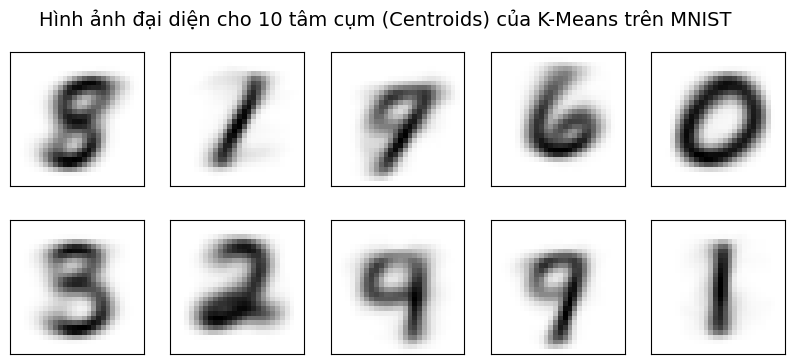

Accuracy sau khi đối chiếu cụm với nhãn thật : 0.5887
Silhouette Score của phân cụm K-Means        : 0.0588

Classification Report (So sánh kết quả K-Means và Nhãn thực tế):

              precision    recall  f1-score   support

           0     0.9271    0.8306    0.8762       980
           1     0.6653    0.9947    0.7973      1135
           2     0.8737    0.6705    0.7588      1032
           3     0.5253    0.6693    0.5886      1010
           4     0.4238    0.4308    0.4273       982
           5     0.0000    0.0000    0.0000       892
           6     0.8948    0.8257    0.8588       958
           7     0.3571    0.7899    0.4918      1028
           8     0.4622    0.5647    0.5083       974
           9     0.0000    0.0000    0.0000      1009

    accuracy                         0.5887     10000
   macro avg     0.5129    0.5776    0.5307     10000
weighted avg     0.5187    0.5887    0.5384     10000



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


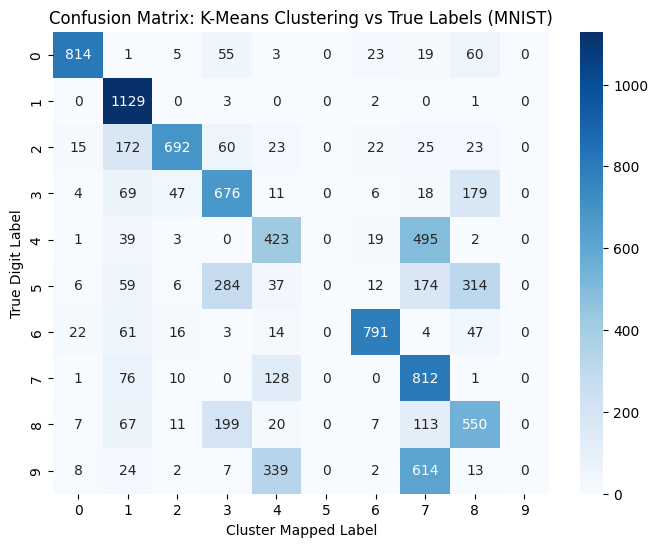

In [ ]:
# ==================== BÀI 5 (TRANG 26) ====================
print("Họ tên: Phan Công Trí - MSSV: 6451071080")

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, silhouette_score
from scipy.stats import mode
from tensorflow.keras.datasets import mnist

# 1. Đọc dữ liệu MNIST (Lấy tập test 10.000 mẫu để chạy K-Means nhanh và trực quan, hoặc toàn bộ)
(train_images, train_labels), (test_images, test_labels) = mnist.load_data()

# Làm phẳng ảnh 28x28 thành vector 784 chiều và chuẩn hóa về [0, 1]
X_mnist = test_images.reshape(test_images.shape[0], -1) / 255.0
y_mnist = test_labels

print("Kích thước dữ liệu đưa vào gom cụm K-Means:", X_mnist.shape)

# 2. Thực hiện gom cụm K-Means với k = 10 (tương ứng 10 chữ số từ 0 đến 9)
kmeans = KMeans(n_clusters=10, n_init=10, random_state=42)
clusters = kmeans.fit_predict(X_mnist)

# Hiển thị hình ảnh 10 tâm cụm (Centroids)
fig, ax = plt.subplots(2, 5, figsize=(10, 4))
centers = kmeans.cluster_centers_.reshape(10, 28, 28)
for axi, center in zip(ax.flat, centers):
    axi.set(xticks=[], yticks=[])
    axi.imshow(center, interpolation='nearest', cmap=plt.cm.binary)
plt.suptitle("Hình ảnh đại diện cho 10 tâm cụm (Centroids) của K-Means trên MNIST", fontsize=14)
plt.show()

# 3. Ánh xạ nhãn cụm (Cluster ID) sang nhãn thực tế (True Digit Label) phổ biến nhất trong cụm đó
labels_mapped = np.zeros_like(clusters)
for i in range(10):
    mask = (clusters == i)
    if np.sum(mask) > 0:
        labels_mapped[mask] = mode(y_mnist[mask], keepdims=True)[0]

# 4. So sánh kết quả gom cụm với nhãn lớp có sẵn
acc = accuracy_score(y_mnist, labels_mapped)
sil = silhouette_score(X_mnist, clusters)
print(f"Accuracy sau khi đối chiếu cụm với nhãn thật : {acc:.4f}")
print(f"Silhouette Score của phân cụm K-Means        : {sil:.4f}")

print("\nClassification Report (So sánh kết quả K-Means và Nhãn thực tế):\n")
print(classification_report(y_mnist, labels_mapped, digits=4))

# 5. Vẽ Confusion Matrix
cm = confusion_matrix(y_mnist, labels_mapped)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix: K-Means Clustering vs True Labels (MNIST)')
plt.xlabel('Cluster Mapped Label')
plt.ylabel('True Digit Label')
plt.show()